# Paper Figures: Figure S1 - Movement Analysis (legacy)

This notebook generates publication-ready figures for the Bazzino & Roitman sodium appetite manuscript using data assembled by `src/assemble_all_data.py`.

**Figure 1: Behavioral Analysis** — Movement analysis showing heatmaps and summary plots for replete and deplete conditions across sodium concentrations.

In [1]:
from pathlib import Path
import sys
# Add src to path for importing local modules
sys.path.insert(0, str(Path("../src").resolve()))
from data_io import load_assembled

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
from scipy import stats
from trompy import zscore
from extract_behav_parameters import smooth_array



from figure_config import (
    configure_matplotlib,
    COLORS,
    HEATMAP_CMAP_DIV,
    HEATMAP_CMAP_RED,
    HEATMAP_CMAP_BLUE,
    DATAFOLDER,
    FIGSFOLDER,
    BEHAV_SMOOTH_WINDOW,
    SAVE_FIGS,
)
from figure_plotting import (
    smooth_array,
    get_heatmap_data,
    get_mean_snips,
    get_auc,
    init_heatmap_figure,
    init_snips_figure,
    make_heatmap,
    plot_snips,
    plot_auc_summary,
    save_figure_atomic,
    print_auc_stats,
    calculate_ylims,
    make_correlation_plot_behav,
)

# Configure matplotlib
configure_matplotlib()
colors = COLORS  # Use shared color palette
custom_cmap_red = HEATMAP_CMAP_RED  # Use shared colormap
custom_cmap_blue = HEATMAP_CMAP_BLUE  # Use shared colormap

custom_cmap = HEATMAP_CMAP_DIV  # Use shared colormap

SAVE_FIGS = False

## Load Assembled Data

Load the complete dataset from the pickle file generated by the assembly script.

In [2]:
assembled_data_path = DATAFOLDER / "assembled"

data = load_assembled(assembled_data_path)

# Extract main components
x_array = data["x_array"]
snips_photo = data["snips_photo"]
snips_movement = data["snips_movement"]
snips_angvel = data["snips_angvel"]

fits_df = data["fits_df"]
params = data.get("params", {})
metadata = data.get("metadata", {})

print("Loaded assembled data from data/assembled")
print(f"\nData structure:")
print(f"  - x_array shape: {x_array.shape}")
print(f"  - snips_photo shape: {snips_photo.shape}")
print(f"  - snips_angvel shape: {snips_angvel.shape}")
print(f"  - snips_movement shape: {snips_movement.shape}")
print(f"  - x_array columns: {x_array.columns.tolist()}")
print(f"  - Number of trials: {len(x_array)}")

Loaded assembled data from data/assembled

Data structure:
  - x_array shape: (1960, 30)
  - snips_photo shape: (1960, 200)
  - snips_angvel shape: (1960, 200)
  - snips_movement shape: (1960, 200)
  - x_array columns: ['trial', 'id', 'condition', 'infusiontype', 'sex', 'movement_mean', 'movement_std', 'angvel_mean', 'angvel_std', 'simba_raw_mean', 'simba_zscore_mean', 'simba_median_balance', 'simba_median_balance_binarized', 'simba_median_balance_quantized', 'cluster_photo', 'clusterness_photo', 'euclidean_diff', 'auc_snips', 'auc_snips_early', 'auc_snips_late', 'auc_movement', 'auc_angvel', 'time_moving', 'time_above_angvel_threshold', 'time_moving_raw', 'realigned_trials_da', 'realigned_trials_da_velocity', 'realigned_trials_da_cluster', 'realigned_trials_behav', 'trial_aligned']
  - Number of trials: 1960


## Figure 1: Behavioral Analysis — Movement Metrics

Analysis of behavioral responses (movement) showing heatmaps, snip time series, and summary AUC metrics across replete and deplete sodium conditions, separated by infusion type (10NaCl vs 45NaCl).

In [3]:
def zscore_to_entire_session(snips, x_array, param_name):

    mean = x_array[param_name + "_mean"].values
    std = x_array[param_name + "_std"].values
    snips_zscored = (snips - mean[:, np.newaxis]) / std[:, np.newaxis]

    return snips_zscored

In [4]:
# Smoothing angvel data and zscoring for plotting
snips_angvel_smoothed = smooth_array(snips_angvel, window_size=BEHAV_SMOOTH_WINDOW)
# snips_angvel_zscored = zscore(snips_angvel_smoothed, baseline_points=50)
# snips_angvel_zscored = zscore_to_entire_session(snips_angvel, x_array, "angvel")  # Z-score using entire session stats
# snips_angvel_smoothed = smooth_array(snips_angvel_zscored, window_size=BEHAV_SMOOTH_WINDOW)
snips_to_plot = np.array(snips_movement)  # Use smoothed and z-scored data for all subsequent analyses and plotting

# Parameters for visualization - MOVEMENT
# Use dynamic scaling based on actual data ranges (asymmetric, not symmetric)
# This ensures heatmaps use the full range of your data without artificial symmetry
vmin = np.nanpercentile(snips_movement, 5)  # 5th percentile for lower bound
vmax = np.nanpercentile(snips_movement, 95)  # 95th percentile for upper bound
vlim = (vmin, vmax)
print(f"Calculated asymmetric vlims: vmin={vmin:.4f}, vmax={vmax:.4f}")
# vlim = (-0.75, 0.75) # for zscored data
vlim = (1, 6)

# Calculate dynamic y-limits based on all snips data - MOVEMENT
print("\n" + "="*60)
print("CALCULATING Y-LIMITS FOR TIME SERIES PLOTS")
print("="*60)

# Get all condition/infusion combinations to compute limits
rep_10, rep_45 = get_mean_snips(snips_movement, x_array, "replete")
dep_10, dep_45 = get_mean_snips(snips_movement, x_array, "deplete")

# Calculate y-limits based on all snips with 5% padding
calc_ylims = calculate_ylims([rep_10, rep_45, dep_10, dep_45], pad_percentage=5)

print(f"  Data range (min, max): ({np.nanmin(snips_movement):.4f}, {np.nanmax(snips_movement):.4f})")
print(f"  Calculated y-limits: {calc_ylims}")
print("="*60 + "\n")

# Use calculated limits or override with fixed values if preferred
ylims = calc_ylims
ylims = (0, 8)

Calculated asymmetric vlims: vmin=0.6249, vmax=11.6887

CALCULATING Y-LIMITS FOR TIME SERIES PLOTS
  Data range (min, max): (0.1945, 372.4277)
  Calculated y-limits: (np.float64(0.25943394567546385), np.float64(14.322430746004098))



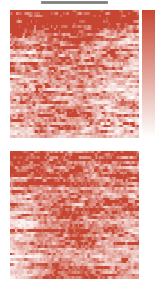

In [5]:
### 1A. Heatmaps — Replete Condition

f, ax1, ax2, cbar_ax = init_heatmap_figure()

# Replete + 10NaCl
heatmap_data_rep_10 = get_heatmap_data(snips_to_plot, x_array, "replete", "10NaCl")
replete_10_auc = get_auc(heatmap_data_rep_10)
make_heatmap(heatmap_data_rep_10, ax1, vlim, inf_bar=True, cmap=custom_cmap_red)

# Replete + 45NaCl
heatmap_data_rep_45 = get_heatmap_data(snips_to_plot, x_array, "replete", "45NaCl")
replete_45_auc = get_auc(heatmap_data_rep_45)
make_heatmap(heatmap_data_rep_45, ax2, vlim, cbar_ax=cbar_ax, cmap=custom_cmap_red)

if SAVE_FIGS:
    save_figure_atomic(f, "figS1_heatmap_movement_replete", FIGSFOLDER)

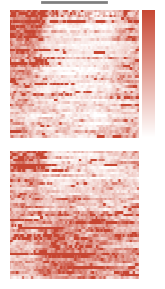

In [6]:
### 1B. Heatmaps — Deplete Condition

f, ax1, ax2, cbar_ax = init_heatmap_figure()

# Deplete + 10NaCl
heatmap_data_dep_10 = get_heatmap_data(snips_to_plot, x_array, "deplete", "10NaCl")
deplete_10_auc = get_auc(heatmap_data_dep_10)
make_heatmap(heatmap_data_dep_10, ax1, vlim, inf_bar=True, cmap=custom_cmap_red)

# Deplete + 45NaCl
heatmap_data_dep_45 = get_heatmap_data(snips_to_plot, x_array, "deplete", "45NaCl")
deplete_45_auc = get_auc(heatmap_data_dep_45)
make_heatmap(heatmap_data_dep_45, ax2, vlim, cbar_ax=cbar_ax, cmap=custom_cmap_red)

if SAVE_FIGS:
    save_figure_atomic(f, "figS1_heatmap_movement_deplete", FIGSFOLDER)

Z-scored Angular Velocity - Symmetric vlims: vmin=-5.9242, vmax=5.9242


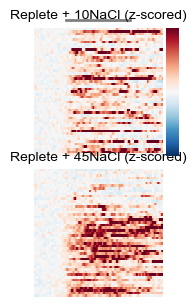

In [7]:
### Z-scored Angular Velocity (baseline normalized) - Replete Condition

# Z-score angular velocity to baseline (first 50 bins)
baseline_end = 50
snips_movement_zscored = zscore(snips_movement, baseline_points=50)
snips_movement_zscored = np.array(snips_movement_zscored)

# Calculate symmetric vlims for z-scored data
vmin_zscored = np.nanpercentile(snips_movement_zscored, 5)
vmax_zscored = np.nanpercentile(snips_movement_zscored, 95)
# Make symmetric around zero
vmax_zscored = max(abs(vmin_zscored), abs(vmax_zscored))
vmin_zscored = -vmax_zscored
vlim_zscored = (vmin_zscored, vmax_zscored)

print(f"Z-scored Angular Velocity - Symmetric vlims: vmin={vmin_zscored:.4f}, vmax={vmax_zscored:.4f}")

f, ax1, ax2, cbar_ax = init_heatmap_figure()

# Replete + 10NaCl (z-scored)
heatmap_data_rep_10_zscored = get_heatmap_data(snips_movement_zscored, x_array, "replete", "10NaCl")
make_heatmap(heatmap_data_rep_10_zscored, ax1, vlim_zscored, inf_bar=True, cmap='RdBu_r')

# Replete + 45NaCl (z-scored)
heatmap_data_rep_45_zscored = get_heatmap_data(snips_movement_zscored, x_array, "replete", "45NaCl")
make_heatmap(heatmap_data_rep_45_zscored, ax2, vlim_zscored, cbar_ax=cbar_ax, cmap='RdBu_r')

ax1.set_title("Replete + 10NaCl (z-scored)", fontsize=10)
ax2.set_title("Replete + 45NaCl (z-scored)", fontsize=10)

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_heatmap_movement_zscored_replete", FIGSFOLDER)

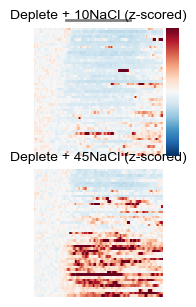

In [8]:
### Z-scored Angular Velocity (baseline normalized) - Deplete Condition

f, ax1, ax2, cbar_ax = init_heatmap_figure()

# Deplete + 10NaCl (z-scored)
heatmap_data_dep_10_zscored = get_heatmap_data(snips_movement_zscored, x_array, "deplete", "10NaCl")
make_heatmap(heatmap_data_dep_10_zscored, ax1, vlim_zscored, inf_bar=True, cmap='RdBu_r')

# Deplete + 45NaCl (z-scored)
heatmap_data_dep_45_zscored = get_heatmap_data(snips_movement_zscored, x_array, "deplete", "45NaCl")
make_heatmap(heatmap_data_dep_45_zscored, ax2, vlim_zscored, cbar_ax=cbar_ax, cmap='RdBu_r')

ax1.set_title("Deplete + 10NaCl (z-scored)", fontsize=10)
ax2.set_title("Deplete + 45NaCl (z-scored)", fontsize=10)

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_heatmap_movement_zscored_deplete", FIGSFOLDER)

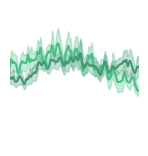

In [9]:
### 1C. Time Series Snips — Replete Condition

# Get animal-averaged snips for replete
snips_rep_10, snips_rep_45 = get_mean_snips(snips_to_plot, x_array, "replete")

f, ax = init_snips_figure()
plot_snips(snips_rep_10, snips_rep_45, ax, colors[0], colors[1], ylims)

if SAVE_FIGS:
    save_figure_atomic(f, "figS1_snips_movement_replete", FIGSFOLDER)

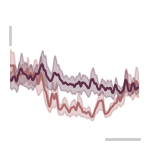

In [10]:
### 1D. Time Series Snips — Deplete Condition

# Get animal-averaged snips for deplete
snips_dep_10, snips_dep_45 = get_mean_snips(snips_to_plot, x_array, "deplete")

f, ax = init_snips_figure()
plot_snips(snips_dep_10, snips_dep_45, ax, colors[2], colors[3], ylims, yscalebar=[6,7], xscalebar=True)

if SAVE_FIGS:
    save_figure_atomic(f, "figS1_snips_movement_deplete", FIGSFOLDER)

In [11]:
from assemble_shap_dfs import assemble_shap_dfs

DATAFOLDER = Path("../data/shap_values")
df_shap, df_shap_raw, feature_summary = assemble_shap_dfs(DATAFOLDER)

In [12]:
feature_summary.shape

(153, 21)

In [13]:
feature_summary

,feature,mean_shap,importance,variability,mean_shap_appetitive,mean_shap_non_appetitive,raw_mean,raw_sd,raw_min,raw_max,...,class_difference,signed_importance,group,bodypart,timewindow,reverse_coded,aligned_signed_importance,display_group,cumulative_importance,reverse_cumulative_importance
0,Total_movement_M1_mean_10,0.005214,0.014481,0.016180,0.017726,-0.007299,7.596502,11.718850,0.193900,117.094597,...,0.025026,-0.014481,movement,whole rat,10,False,-0.014481,movement,0.033933,9.660667e-01
1,Total_movement_M1_mean_10_percentile_rank,0.007377,0.014088,0.016186,0.020256,-0.005501,2.800796,11.598030,-106.194603,12.291800,...,0.025757,0.014088,movement,whole rat,10,True,-0.014088,"movement, reverse coded",0.066946,9.330540e-01
2,Total_movement_M1_sum_10,0.005153,0.013934,0.015545,0.017296,-0.006991,75.965021,117.188490,1.939300,1170.946167,...,0.024288,-0.013934,movement,whole rat,10,False,-0.013934,movement,0.099599,9.004015e-01
3,Head_base_movement_M1_mean_10,0.005090,0.012353,0.013405,0.015754,-0.005574,1.331906,2.133838,0.000000,19.008600,...,0.021328,-0.012353,movement,head base,10,False,-0.012353,movement,0.128547,8.714534e-01
4,Head_base_movement_M1_sum_10,0.004991,0.011776,0.012701,0.015203,-0.005222,13.319071,21.338366,0.000000,190.085800,...,0.020425,-0.011776,movement,head base,10,False,-0.011776,movement,0.156142,8.438575e-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
148,Movement_mouse_nose,0.000713,0.000838,0.001036,0.001263,0.000162,1.891705,3.166628,0.000000,25.100100,...,0.001101,0.000838,movement,nose,none,False,0.000838,movement,0.993653,6.346736e-03
149,Tail_base_movement_M1_median_2,0.000552,0.000708,0.001020,0.000946,0.000158,1.174918,5.644485,0.000000,74.922997,...,0.000789,0.000708,movement,tail base,2,False,0.000708,movement,0.995311,4.688798e-03
150,Tail_base_movement_M1_sum_2,0.000556,0.000707,0.001035,0.000959,0.000153,2.349835,11.288970,0.000000,149.846100,...,0.000807,0.000707,movement,tail base,2,False,0.000707,movement,0.996969,3.031426e-03
151,Tail_base_movement_M1_mean_2,0.000546,0.000694,0.001017,0.000937,0.000156,1.174918,5.644485,0.000000,74.922997,...,0.000781,0.000694,movement,tail base,2,False,0.000694,movement,0.998595,1.405267e-03


In [14]:
# set colours for strips

bodypart_colors = {
    "nose": "#d95f02",
    "tail base": "#1b9e77",
    "head base": "#7570b3",
    "ears": "#e7298a",
    "whole rat": "#a6761d",
    "other": "#bdbdbd",
}
bodypart_codes = {name: code for code, name in enumerate(bodypart_colors)}
bodypart_values = feature_summary["bodypart"].map(bodypart_codes).to_numpy()

window_order = ["none", "2", "5", "6", "7.5", "10"]
window_colors = ["#d9d9d9", "#440154", "#31688e", "#35b779", "#90d743", "#fde725"]
window_codes = {name: code for code, name in enumerate(window_order)}
window_values = feature_summary["timewindow"].map(window_codes).to_numpy()  # unchanged

# window sizes are frame counts at 10 fps; 7.5 is truncated to 7 frames by the extractor
window_seconds = {"none": "none", "2": "0.2 s", "5": "0.5 s", "6": "0.6 s", "7.5": "0.7 s", "10": "1.0 s"}

In [15]:
feature_summary["timewindow"].unique()

<ArrowStringArray>
['10', '7.5', '6', 'none', '5', '2']
Length: 6, dtype: str

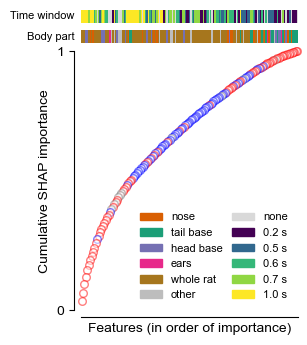

In [16]:
f, [ax_window, ax_bp, ax] = plt.subplots(
    figsize=(3.1, 3.8),
    nrows=3,
    sharex=True,
    gridspec_kw={"height_ratios": [0.05, 0.05, 1], "hspace": 0.08,
                 "left": 0.2, "top": 0.9},
)

ax_bp.imshow(
    bodypart_values[None, ::-1],
    aspect="auto",
    interpolation="none",
    cmap=ListedColormap(list(bodypart_colors.values())),
    vmin=-0.5,
    vmax=len(bodypart_colors) - 0.5,
)
ax_window.imshow(
    window_values[None, ::-1],
    aspect="auto",
    interpolation="none",
    cmap=ListedColormap(window_colors),
    vmin=-0.5,
    vmax=len(window_order) - 0.5,
)

ax_window.text(-0.03, 0.5, "Time window", va="center", ha="right", fontsize=8, transform=ax_window.transAxes)
ax_bp.text(-0.03, 0.5, "Body part", va="center", ha="right", fontsize=8, transform=ax_bp.transAxes)

for axis in [ax_bp, ax_window]:
    axis.set_xticks([])
    axis.set_yticks([])
    axis.set_ylim(-0.5, 0.5)
    axis.set_xlim(len(feature_summary) - 0.5, -0.5)

for xtick, row in enumerate(feature_summary.iloc[::-1].itertuples(index=False)):
    color = {"movement": "red", "geometry": "blue"}.get(row.group, "grey")
    ax.scatter(
        xtick,
        row.cumulative_importance,
        edgecolors=color,
        facecolors="w",
        alpha=0.5,
        s=30,
        clip_on=False,
    )
    
ax.set_ylim(0, 1)
#ax.invert_yaxis()

ax.set_ylabel("Cumulative SHAP importance")

bodypart_legend = [
    Patch(color=color, label=label)
    for label, color in bodypart_colors.items()
]
bodypart_legend_artist = ax.legend(
    handles=bodypart_legend,
    loc="lower right",
    bbox_to_anchor=(0.7, 0),
    frameon=False,
    fontsize=8,
)

window_legend = [
    Patch(color=color, label=window_seconds[window])
    for window, color in zip(window_order, window_colors)
]
ax.legend(
    handles=window_legend,
    loc="lower right",
    bbox_to_anchor=(1, 0),
    frameon=False,
    fontsize=8,
)
ax.add_artist(bodypart_legend_artist)

ax.set_xlabel("Features (in order of importance)")
ax.set_yticks([0, 1], labels=["0", "1"])

sns.despine(ax=ax_bp, left=True, bottom=True)
sns.despine(ax=ax_window, left=True, bottom=True)
sns.despine(ax=ax, offset=5)
for axis in [ax1, ax_window, ax2]:
    axis.set_yticks([])
    
save_figure_atomic(f, "figS1_cumul_shap_importance", FIGSFOLDER)

In [17]:
x_array["total_movement"] = snips_movement[:,50:150].sum(axis=1)

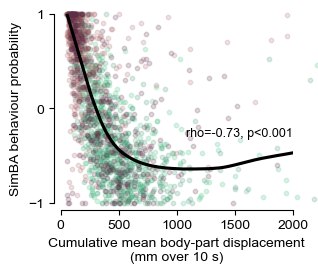

In [18]:
f, ax = plt.subplots(figsize=(3, 3),
                     gridspec_kw={"bottom": 0.25})

x = x_array["total_movement"]
y = x_array["simba_median_balance"]
rho, p = stats.spearmanr(x, y)
p_label = "p<0.001" if p < 0.001 else f"p={p:.3f}"

CORRELATION_FIT = "lowess"  # Choose: "linear", "lowess", or "none"
if CORRELATION_FIT == "linear":
    sns.regplot(x=x, y=y, ax=ax, scatter=False, ci=95,
                line_kws={"color": "k"})
elif CORRELATION_FIT == "lowess":
    sns.regplot(x=x, y=y, ax=ax, scatter=False, lowess=True, ci=95,
                line_kws={"color": "k"})
elif CORRELATION_FIT != "none":
    raise ValueError("CORRELATION_FIT must be 'linear', 'lowess', or 'none'")

for pair, color in zip([("replete", "10NaCl"), ("replete", "45NaCl"), ("deplete", "10NaCl"), ("deplete", "45NaCl")], colors):
    mask = (x_array["condition"] == pair[0]) & (x_array["infusiontype"] == pair[1])
    ax.scatter(x[mask], y[mask], color=color, s=10, alpha=0.2, label=f"{pair[0]} + {pair[1]}", clip_on=False)
# ax.scatter(x, y, color="k", s=10, alpha=0.05, clip_on=False)

ax.set_xlim(0, 2000)
ax.text(1, 0.4, f"rho={rho:.2f}, {p_label}", transform=ax.transAxes,
        color="k", fontsize=9, va="top", ha="right")

ax.set_ylim(-1, 1)
ax.set_yticks([-1, 0, 1])
ax.set_xlabel("Cumulative mean body-part displacement\n(mm over 10 s)")
ax.set_ylabel("SimBA behaviour probability")

sns.despine(offset=5)

save_figure_atomic(f, "figS1_correlation_movement_simba", FIGSFOLDER)

Pearson correlation: -0.7036876338686753 6.055996446662855e-293 p<0.001
Spearman correlation: -0.7349932259088763 0.0 p<0.001


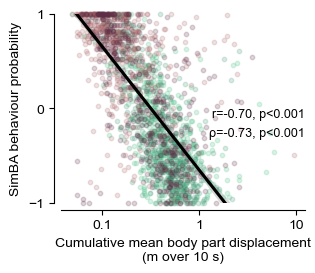

In [19]:
f, ax = plt.subplots(figsize=(3, 3),
                     gridspec_kw={"bottom": 0.25, "right": 0.94})

x = x_array["total_movement"]
y = x_array["simba_median_balance"]


x = np.log10(x)  # Apply log transformation to y-axis data

CORRELATION_FIT = "linear"  # Choose: "linear", "lowess", or "none"
if CORRELATION_FIT == "linear":
    sns.regplot(x=x, y=y, ax=ax, scatter=False, ci=95,
                line_kws={"color": "k"})
elif CORRELATION_FIT == "lowess":
    sns.regplot(x=x, y=y, ax=ax, scatter=False, lowess=True, ci=95,
                line_kws={"color": "k"})
elif CORRELATION_FIT != "none":
    raise ValueError("CORRELATION_FIT must be 'linear', 'lowess', or 'none'")

for pair, color in zip([("replete", "10NaCl"), ("replete", "45NaCl"), ("deplete", "10NaCl"), ("deplete", "45NaCl")], colors):
    mask = (x_array["condition"] == pair[0]) & (x_array["infusiontype"] == pair[1])
    ax.scatter(x[mask], y[mask], color=color, s=10, alpha=0.2, label=f"{pair[0]} + {pair[1]}", clip_on=False)

ax.set_ylim(-1, 1)
ax.set_yticks([-1, 0, 1])
ax.set_xlabel("Cumulative mean body part displacement\n(m over 10 s)")
ax.set_ylabel("SimBA behaviour probability")

# ax.set_xlim(0, 2000)
ax.set_xticks([2, 3, 4], labels=["0.1", "1", "10"])  # Set x-ticks for log scale

sns.despine(offset=5)


r, p = stats.pearsonr(x, y)
p_label = "p<0.001" if p < 0.001 else f"p={p:.3f}"
print("Pearson correlation:", r, p, p_label)

rho, p = stats.spearmanr(x, y)
p_label_spearman = "p<0.001" if p < 0.001 else f"p={p:.3f}"
print("Spearman correlation:", rho, p, p_label_spearman)

ax.text(1, 0.5, f"r={r:.2f}, {p_label}", transform=ax.transAxes,
        color="k", fontsize=9, va="top", ha="right")

ax.text(1, 0.4, f"ρ={rho:.2f}, {p_label_spearman}", transform=ax.transAxes,
        color="k", fontsize=9, va="top", ha="right")

save_figure_atomic(f, "figS1_correlation_movement_simba_logaxis", FIGSFOLDER)

In [20]:
def get_time_moving_by_group(x_array, condition, infusiontype):
    
    return (
        x_array
        .query("condition == @condition and infusiontype == @infusiontype")
        .groupby("id")
        .time_moving
        .mean()
        .values
    )
    
def get_movement_auc_by_group(x_array, condition, infusiontype):
    
    return (
        x_array
        .query("condition == @condition and infusiontype == @infusiontype")
        .groupby("id")
        .movement_auc
        .mean()
        .values
    )


Figure 1 — Movement Summary Statistics
Replete + 10NaCl (n=10)        (n=10):    0.50 ± 0.01
Replete + 45NaCl (n=10)        (n=10):    0.54 ± 0.04
Deplete + 10NaCl (n=10)        (n=10):    0.14 ± 0.02
Deplete + 45NaCl (n=10)        (n=10):    0.37 ± 0.04


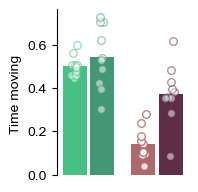

In [21]:
### 1E. AUC Summary — Bar Plot with Individual Data Points

# Organize AUCs by condition
replete_aucs = [get_time_moving_by_group(x_array, "replete", "10NaCl"),
                get_time_moving_by_group(x_array, "replete", "45NaCl")]
deplete_aucs = [get_time_moving_by_group(x_array, "deplete", "10NaCl"),
                get_time_moving_by_group(x_array, "deplete", "45NaCl")]
                                         
aucs = [replete_aucs, deplete_aucs]

f, ax = plot_auc_summary(aucs, colors, ylabel="Time moving ")
# f.suptitle("Ang vel — AUC Summary", fontsize=10)

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_auc_movement_summary", FIGSFOLDER)

# Print summary statistics
auc_labels = [
    f"Replete + 10NaCl (n={len(replete_aucs[0])})",
    f"Replete + 45NaCl (n={len(replete_aucs[1])})",
    f"Deplete + 10NaCl (n={len(deplete_aucs[0])})",
    f"Deplete + 45NaCl (n={len(deplete_aucs[1])})"
]
auc_arrays = [replete_aucs[0], replete_aucs[1], deplete_aucs[0], deplete_aucs[1]]
print_auc_stats(auc_arrays, auc_labels, title="Figure 1 — Movement Summary Statistics")

r = -0.69, p = 0.000
r = -0.01, p = 0.959
r = 0.03, p = 0.828
r = 0.90, p = 0.000


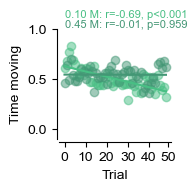

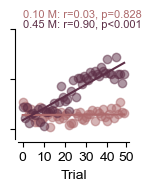

In [22]:
### Correlation plots — Time moving across trials

def make_auc_data_per_trial(x_array, condition, infusiontype):
    
    return (
        x_array
        .query("condition == @condition & infusiontype == @infusiontype")
        .groupby("trial")
        .time_moving
        .mean()
        .values
    )
    
replete_10 = make_auc_data_per_trial(x_array, "replete", "10NaCl")
replete_45 = make_auc_data_per_trial(x_array, "replete", "45NaCl")
deplete_10 = make_auc_data_per_trial(x_array, "deplete", "10NaCl")
deplete_45 = make_auc_data_per_trial(x_array, "deplete", "45NaCl")

f = make_correlation_plot_behav(replete_10, replete_45, colors[0], colors[1], yaxis=True)
if SAVE_FIGS:
    save_figure_atomic(f, "fig1_correlation_movement_replete", FIGSFOLDER)
    
f = make_correlation_plot_behav(deplete_10, deplete_45, colors[2], colors[3])
if SAVE_FIGS:
    save_figure_atomic(f, "fig1_correlation_movement_deplete", FIGSFOLDER)

In [23]:
### Model fits on time-moving by trial data with fit-quality checks
from scipy.optimize import curve_fit
from scipy.stats import pearsonr

def _linear_model(x, m, b):
    return m * x + b

def _exp_model(x, a, b, c):
    return a * np.exp(b * x) + c

def _sigmoid_model(x, L, k, x0, b):
    z = np.clip(-k * (x - x0), -60, 60)
    return L / (1 + np.exp(z)) + b

def _safe_pearson(y_true, y_pred):
    if np.allclose(np.std(y_true), 0) or np.allclose(np.std(y_pred), 0):
        return np.nan, np.nan
    return pearsonr(y_true, y_pred)

def _model_metrics(y_true, y_pred, n_params):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    n = len(y_true)
    residuals = y_true - y_pred
    sse = np.nansum(residuals ** 2)
    sse = max(float(sse), 1e-12)
    rmse = np.sqrt(sse / n) if n > 0 else np.nan
    aic = n * np.log(sse / n) + 2 * n_params if n > 0 else np.nan
    bic = n * np.log(sse / n) + n_params * np.log(n) if n > 1 else np.nan
    aicc = aic + (2 * n_params * (n_params + 1)) / (n - n_params - 1) if n > (n_params + 1) else np.nan
    return rmse, aic, aicc, bic

def _fit_linear(x, y):
    try:
        m, b = np.polyfit(x, y, 1)
        yhat = _linear_model(x, m, b)
        r, p = _safe_pearson(y, yhat)
        rmse, aic, aicc, bic = _model_metrics(y, yhat, n_params=2)
        return {"r": r, "p": p, "rmse": rmse, "aic": aic, "aicc": aicc, "bic": bic, "params": np.array([m, b]), "pcov": None}
    except Exception:
        return {"r": np.nan, "p": np.nan, "rmse": np.nan, "aic": np.nan, "aicc": np.nan, "bic": np.nan, "params": np.array([np.nan, np.nan]), "pcov": None}

def _fit_curve(model_name, model_func, x, y):
    try:
        if model_name == "exponential":
            p0 = [np.ptp(y) if np.ptp(y) != 0 else 1.0, 0.05, np.min(y)]
            bounds = ([-np.inf, -np.inf, -np.inf], [np.inf, np.inf, np.inf])
            n_params = 3
        elif model_name == "sigmoidal":
            p0 = [np.ptp(y) if np.ptp(y) != 0 else 1.0, 0.2, np.median(x), np.min(y)]
            bounds = ([-np.inf, -np.inf, np.min(x), -np.inf], [np.inf, np.inf, np.max(x), np.inf])
            n_params = 4
        else:
            raise ValueError(f"Unknown model: {model_name}")

        params, pcov = curve_fit(model_func, x, y, p0=p0, bounds=bounds, maxfev=30000)
        yhat = model_func(x, *params)
        r, p = _safe_pearson(y, yhat)
        rmse, aic, aicc, bic = _model_metrics(y, yhat, n_params=n_params)
        return {"r": r, "p": p, "rmse": rmse, "aic": aic, "aicc": aicc, "bic": bic, "params": params, "pcov": pcov}
    except Exception:
        n_params = 3 if model_name == "exponential" else 4
        return {"r": np.nan, "p": np.nan, "rmse": np.nan, "aic": np.nan, "aicc": np.nan, "bic": np.nan, "params": np.full(n_params, np.nan), "pcov": None}

def _sigmoid_quality_checks(x, params, pcov):
    if params is None or len(params) != 4 or np.any(~np.isfinite(params)):
        return False, "fit_failed", {"x0_interior": False, "k_plausible": False, "ci_finite": False, "asymptotes_covered": False}

    L, k, x0, b = params
    x_min, x_max = float(np.min(x)), float(np.max(x))
    x_range = max(x_max - x_min, 1.0)
    edge_margin = 0.15 * x_range
    x0_interior = (x_min + edge_margin) <= x0 <= (x_max - edge_margin)
    k_plausible = np.isfinite(k) and (0.02 <= abs(k) <= 2.5)

    ci_finite = False
    if pcov is not None:
        diag = np.diag(pcov)
        if np.all(np.isfinite(diag)) and np.all(diag >= 0):
            se = np.sqrt(diag)
            ci_finite = np.all(np.isfinite(se)) and np.all(se > 0)

    amplitude = abs(L)
    if amplitude < 1e-8:
        asymptotes_covered = False
    else:
        lower_asym = min(b, b + L)
        upper_asym = max(b, b + L)
        y_start = _sigmoid_model(np.array([x_min]), L, k, x0, b)[0]
        y_end = _sigmoid_model(np.array([x_max]), L, k, x0, b)[0]

        tol = 0.2
        start_low = abs(y_start - lower_asym) / amplitude <= tol
        start_high = abs(y_start - upper_asym) / amplitude <= tol
        end_low = abs(y_end - lower_asym) / amplitude <= tol
        end_high = abs(y_end - upper_asym) / amplitude <= tol

        start_side = "low" if start_low else ("high" if start_high else None)
        end_side = "low" if end_low else ("high" if end_high else None)
        asymptotes_covered = (start_side is not None) and (end_side is not None) and (start_side != end_side)

    checks = {
        "x0_interior": bool(x0_interior),
        "k_plausible": bool(k_plausible),
        "ci_finite": bool(ci_finite),
        "asymptotes_covered": bool(asymptotes_covered),
    }

    failed = [name for name, ok in checks.items() if not ok]
    is_valid = len(failed) == 0
    reasons = "ok" if is_valid else ";".join(failed)
    return is_valid, reasons, checks

fit_inputs = {
    "Replete + 10NaCl": replete_10,
    "Replete + 45NaCl": replete_45,
    "Deplete + 10NaCl": deplete_10,
    "Deplete + 45NaCl": deplete_45,
}

rows = []
sigmoid_diagnostics = []

for condition_label, y in fit_inputs.items():
    y = np.asarray(y, dtype=float)
    x = np.arange(1, len(y) + 1, dtype=float)

    lin = _fit_linear(x, y)
    rows.append({
        "Condition": condition_label,
        "Model": "Linear",
        "r": lin["r"],
        "p": lin["p"],
        "RMSE": lin["rmse"],
        "AICc": lin["aicc"],
        "BIC": lin["bic"],
        "Sigmoid_valid": np.nan,
        "Sigmoid_flags": "",
    })

    exp_fit = _fit_curve("exponential", _exp_model, x, y)
    rows.append({
        "Condition": condition_label,
        "Model": "Exponential",
        "r": exp_fit["r"],
        "p": exp_fit["p"],
        "RMSE": exp_fit["rmse"],
        "AICc": exp_fit["aicc"],
        "BIC": exp_fit["bic"],
        "Sigmoid_valid": np.nan,
        "Sigmoid_flags": "",
    })

    sig_fit = _fit_curve("sigmoidal", _sigmoid_model, x, y)
    is_valid, reasons, checks = _sigmoid_quality_checks(x, sig_fit["params"], sig_fit["pcov"])
    rows.append({
        "Condition": condition_label,
        "Model": "Sigmoidal",
        "r": sig_fit["r"],
        "p": sig_fit["p"],
        "RMSE": sig_fit["rmse"],
        "AICc": sig_fit["aicc"],
        "BIC": sig_fit["bic"],
        "Sigmoid_valid": is_valid,
        "Sigmoid_flags": reasons,
    })

    L, k, x0, b = sig_fit["params"] if len(sig_fit["params"]) == 4 else [np.nan, np.nan, np.nan, np.nan]
    sigmoid_diagnostics.append({
        "Condition": condition_label,
        "L": L,
        "k": k,
        "x0": x0,
        "b": b,
        "Sigmoid_valid": is_valid,
        "Sigmoid_flags": reasons,
        "x0_interior": checks["x0_interior"],
        "k_plausible": checks["k_plausible"],
        "ci_finite": checks["ci_finite"],
        "asymptotes_covered": checks["asymptotes_covered"],
    })

fit_results = pd.DataFrame(rows)
fit_results["AICc_rank"] = fit_results.groupby("Condition")["AICc"].rank(method="dense")
fit_results["Best_by_AICc"] = fit_results["AICc_rank"] == 1

for col in ["r", "p", "RMSE", "AICc", "BIC", "AICc_rank"]:
    fit_results[col] = fit_results[col].round(4)

print("Model fit results (time moving by trial) with quality checks:")
display(fit_results)

sigmoid_params_table = pd.DataFrame(sigmoid_diagnostics)
sigmoid_params_table[["L", "k", "x0", "b"]] = sigmoid_params_table[["L", "k", "x0", "b"]].round(4)

print("Sigmoidal fit parameters (time moving by trial) with validity checks:")
display(sigmoid_params_table)

Model fit results (time moving by trial) with quality checks:


,Condition,Model,r,p,RMSE,AICc,BIC,Sigmoid_valid,Sigmoid_flags,AICc_rank,Best_by_AICc
0,Replete + 10NaCl,Linear,0.6894,0.0000,0.0780,-245.7654,-242.2426,NaN,,2.0,False
1,Replete + 10NaCl,Exponential,0.6894,0.0000,0.0780,-243.4912,-238.3491,NaN,,3.0,False
2,Replete + 10NaCl,Sigmoidal,0.7808,0.0000,0.0673,-255.6234,-248.9652,False,x0_interior;asymptotes_covered,1.0,True
3,Replete + 45NaCl,Linear,0.0075,0.9593,0.0823,-240.4753,-236.9526,NaN,,1.0,True
4,Replete + 45NaCl,Exponential,0.0075,0.9594,0.0823,-238.2029,-233.0607,NaN,,2.0,False
5,Replete + 45NaCl,Sigmoidal,0.0633,0.6657,0.0821,-236.0211,-229.3629,False,k_plausible,3.0,False
6,Deplete + 10NaCl,Linear,0.0318,0.8280,0.0550,-280.0036,-276.4808,NaN,,2.0,False
7,Deplete + 10NaCl,Exponential,0.0318,0.8281,0.0550,-277.7311,-272.5889,NaN,,3.0,False
8,Deplete + 10NaCl,Sigmoidal,0.4245,0.0024,0.0498,-285.0441,-278.3859,False,x0_interior;k_plausible,1.0,True
9,Deplete + 45NaCl,Linear,0.8955,0.0000,0.0843,-238.1647,-234.6419,NaN,,2.0,False


Sigmoidal fit parameters (time moving by trial) with validity checks:


,Condition,L,k,x0,b,Sigmoid_valid,Sigmoid_flags,x0_interior,k_plausible,ci_finite,asymptotes_covered
0,Replete + 10NaCl,-0.3547,0.1927,7.6261,0.7967,False,x0_interior;asymptotes_covered,False,True,True,False
1,Replete + 45NaCl,-0.0105,-9.9185,21.5358,0.5480,False,k_plausible,True,False,True,True
2,Deplete + 10NaCl,0.0790,-39.2152,5.0500,0.1348,False,x0_interior;k_plausible,False,False,True,True
3,Deplete + 45NaCl,0.4432,0.2290,23.1711,0.1366,True,ok,True,True,True,True


In [24]:
### Best valid model per condition (compact summary)
summary_rows = []

for condition_label, group in fit_results.groupby("Condition"):
    group = group.copy()
    group["Is_valid_for_selection"] = np.where(
        group["Model"] == "Sigmoidal",
        group["Sigmoid_valid"].fillna(False),
        True,
    )

    valid_group = group[group["Is_valid_for_selection"] == True]
    if len(valid_group) > 0 and valid_group["AICc"].notna().any():
        best = valid_group.sort_values("AICc", ascending=True).iloc[0]
        selection_reason = "best_valid_by_AICc"
    else:
        best = group.sort_values("AICc", ascending=True).iloc[0]
        selection_reason = "fallback_no_valid_model"

    summary_rows.append({
        "Condition": condition_label,
        "Selected_Model": best["Model"],
        "Selection_Reason": selection_reason,
        "r": best["r"],
        "p": best["p"],
        "RMSE": best["RMSE"],
        "AICc": best["AICc"],
        "BIC": best["BIC"],
        "Sigmoid_valid": best["Sigmoid_valid"],
        "Sigmoid_flags": best["Sigmoid_flags"],
    })

best_model_summary = pd.DataFrame(summary_rows)
for col in ["r", "p", "RMSE", "AICc", "BIC"]:
    best_model_summary[col] = best_model_summary[col].round(4)

print("Best valid model per condition (AICc-based):")
display(best_model_summary)

Best valid model per condition (AICc-based):


,Condition,Selected_Model,Selection_Reason,r,p,RMSE,AICc,BIC,Sigmoid_valid,Sigmoid_flags
0,Deplete + 10NaCl,Linear,best_valid_by_AICc,0.0318,0.8280,0.0550,-280.0036,-276.4808,NaN,
1,Deplete + 45NaCl,Sigmoidal,best_valid_by_AICc,0.9367,0.0000,0.0663,-256.9810,-250.3228,True,ok
2,Replete + 10NaCl,Linear,best_valid_by_AICc,0.6894,0.0000,0.0780,-245.7654,-242.2426,NaN,
3,Replete + 45NaCl,Linear,best_valid_by_AICc,0.0075,0.9593,0.0823,-240.4753,-236.9526,NaN,



Time Above Threshold Summary Statistics (per-rat means)
Replete + 10NaCl (n=10 rats)   (n=10):    0.54 ± 0.01
Replete + 45NaCl (n=10 rats)   (n=10):    0.57 ± 0.03
Deplete + 10NaCl (n=10 rats)   (n=10):    0.26 ± 0.03
Deplete + 45NaCl (n=10 rats)   (n=10):    0.44 ± 0.04


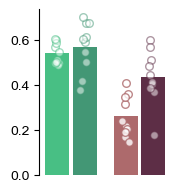

In [25]:
### Time Above Angular Velocity Threshold Summary — Bar Plot (per-rat means)

# Calculate mean time above threshold per rat, then organize by condition/infusion
# This matches the approach used for AUC where we get the mean per rat first

def get_mean_time_above_per_rat(x_array, condition, infusion):
    """Get mean time above threshold per rat for a given condition/infusion."""
    subset = x_array[(x_array['condition'] == condition) & (x_array['infusiontype'] == infusion)]
    time_above_per_rat = subset.groupby('id')['time_above_angvel_threshold'].mean().values
    return time_above_per_rat

# Get per-rat means for each condition/infusion combination
rep_10_time_above = get_mean_time_above_per_rat(x_array, "replete", "10NaCl")
rep_45_time_above = get_mean_time_above_per_rat(x_array, "replete", "45NaCl")
dep_10_time_above = get_mean_time_above_per_rat(x_array, "deplete", "10NaCl")
dep_45_time_above = get_mean_time_above_per_rat(x_array, "deplete", "45NaCl")

# Organize by condition
replete_time_above = [rep_10_time_above, rep_45_time_above]
deplete_time_above = [dep_10_time_above, dep_45_time_above]
time_above_data = [replete_time_above, deplete_time_above]

f, ax = plot_auc_summary(time_above_data, colors, ylabel="")

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_time_above_threshold_summary_perrat", FIGSFOLDER)


# Print summary statistics
time_labels = [
    f"Replete + 10NaCl (n={len(rep_10_time_above)} rats)",
    f"Replete + 45NaCl (n={len(rep_45_time_above)} rats)",
    f"Deplete + 10NaCl (n={len(dep_10_time_above)} rats)",
    f"Deplete + 45NaCl (n={len(dep_45_time_above)} rats)"
]
time_arrays = [rep_10_time_above, rep_45_time_above, dep_10_time_above, dep_45_time_above]
print_auc_stats(time_arrays, time_labels, title="Time Above Threshold Summary Statistics (per-rat means)")